# Exercise 3.4 | The Simplest GLM

You have 30 paired observations of wait times at a coffee shop. Each value is the afternoon wait minus the morning wait, measured in minutes. A positive difference means the afternoon wait was longer. Is there a systematic difference, or is it just noise?

For this exercise, treat the pairs as independent observations from a population of comparable visits. Complete the notebook, then enter your answers in Gradescope.

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

In [2]:
wait_difference = [1.3, 2.4, 2.2, 1.3, 3.0, 2.3, 0.8, 2.7, 2.0, 2.9, 1.7, 1.9, 2.2,
                   2.1, 2.4, 1.7, 1.7, 1.9, 1.7, 2.5, 2.4, 2.2, 1.9, 1.9, 2.7, 1.8,
                   1.8, 2.0, 1.9, 2.1]
data = pd.DataFrame({'wait_difference': wait_difference})

## Explore the Data

**Question 1.** Compute the sample mean and sample standard deviation of the wait time differences, in minutes. Use the sample standard deviation (`ddof=1`).

In [3]:
print(data['wait_difference'].mean())
print(data['wait_difference'].std())

2.0466666666666664
0.4768671710765742


**Question 2.** Make a histogram of the wait time differences. Are the values centered near zero, or somewhere else?

<Axes: xlabel='wait_difference', ylabel='Count'>

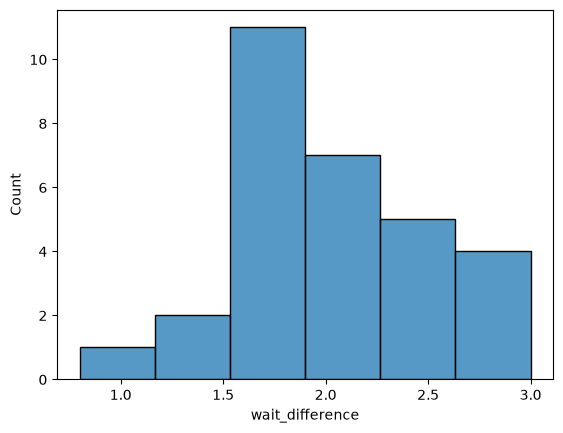

In [4]:
sns.histplot(x='wait_difference', data=data)

Near positive two minutes: afternoon waits tend to be longer{++.++}

## Choosing the Best Prediction

The simplest model predicts every observation with a single number $b$:

$$\hat{y}_i = b$$

The residual for each observation is $e_i = y_i - b$. We measure the model's total "wrongness" with **Mean Squared Error**:

$$MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - b)^2$$

Because the differences are measured in minutes, MSE is measured in squared minutes.

**Question 3.** Compute the MSE when $b = 2.5$.

*Hint: `np.mean((data['wait_difference'] - b)**2)`*

In [5]:
b = 2.5
np.mean((data['wait_difference'] - b)**2)

np.float64(0.42533333333333334)

**Question 4.** Compute the MSE when $b = 1.5$.

In [6]:
b = 1.5
np.mean((data['wait_difference'] - b)**2)

np.float64(0.5186666666666667)

**Question 5.** Compute the MSE when $b = \bar{y}$ (the sample mean). Which of the three values of $b$ gives the smallest MSE?

In [7]:
b = data['wait_difference'].mean()
np.mean((data['wait_difference'] - b)**2)

np.float64(0.21982222222222222)

The sample mean minimizes the MSE.

## Fitting the Model

The intercept-only model is written $y \sim 1$. It finds the value of $b$ that minimizes MSE. We can fit it in Python with `statsmodels`.

**Question 6.** Fit the intercept-only model and print the coefficient table.

*Hint: save `smf.ols('wait_difference ~ 1', data=data).fit()` as `model`, then use `print(model.summary().tables[1])`.*

In [8]:
model = smf.ols('wait_difference ~ 1', data=data).fit()
print(model.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.0467      0.087     23.508      0.000       1.869       2.225


**Question 7.** Compare the intercept coefficient (`coef`) to the sample mean you calculated in Question 1. What do you notice?

What null hypothesis does the p-value on the intercept test?

{++The++} intercept equals the sample mean: the model's best prediction is $\bar{y}$.

$H_0: \beta_0 = 0$. The population mean afternoon-minus-morning wait time difference is zero{++.++}